<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/BIS/blob/main/1BF24CS062_particle_swarm_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install numpy matplotlib pillow scipy scikit-image


Saving test.jpg to test.jpg
STANDARD PSO
Filter strength: 0.6055
MSE: 0.004295
PSNR: 23.67 dB

IMPROVED PSO (IPSO)
Filter strength: 0.6058
MSE: 0.004295
PSNR: 23.67 dB


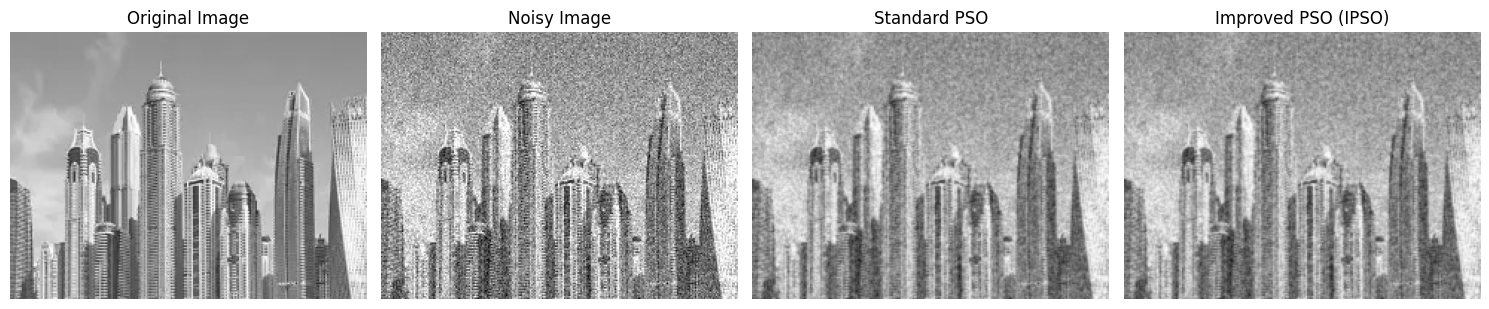

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import mean_squared_error
from google.colab import files
import io

# Upload an image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image and convert to grayscale
original = np.asarray(
    Image.open(io.BytesIO(uploaded[filename])).convert("L"),
    dtype=np.float64
) / 255.0

# Add Gaussian noise
np.random.seed(42)
noise_level = 0.10

noisy = np.clip(
    original + np.random.normal(0, noise_level, original.shape),
    0, 1
)

# Apply Gaussian filter
def denoise(image, sigma):
    if sigma <= 0:
        return image.copy()
    return gaussian_filter(image, sigma=sigma)

# Calculate image error
def fitness(sigma):
    result = denoise(noisy, sigma)
    return mean_squared_error(original, result)

# Particle Swarm Optimization
def run_pso(improved=False, particles=12, iterations=35):
    rng = np.random.default_rng(123)

    lower, upper = 0.0, 3.0
    c1, c2 = 2.05, 2.05
    w = 0.7
    phi = c1 + c2
    K = 2 / abs(2 - phi - np.sqrt(phi**2 - 4 * phi))

    position = rng.uniform(lower, upper, particles)
    velocity = rng.uniform(-0.5, 0.5, particles)

    pbest = position.copy()
    pbest_score = np.array([fitness(x) for x in position])

    best_index = np.argmin(pbest_score)
    gbest = pbest[best_index]
    gbest_score = pbest_score[best_index]

    for _ in range(iterations):
        r1 = rng.random(particles)
        r2 = rng.random(particles)

        cognitive = c1 * r1 * (pbest - position)
        social = c2 * r2 * (gbest - position)

        if improved:
            velocity = K * (
                velocity + cognitive + social
            )
        else:
            velocity = (
                w * velocity + cognitive + social
            )

        position = np.clip(
            position + velocity, lower, upper
        )

        scores = np.array([fitness(x) for x in position])

        better = scores < pbest_score
        pbest[better] = position[better]
        pbest_score[better] = scores[better]

        best_index = np.argmin(pbest_score)

        if pbest_score[best_index] < gbest_score:
            gbest = pbest[best_index]
            gbest_score = pbest_score[best_index]

    return float(gbest)

# Optimize filter strength
standard_sigma = run_pso(improved=False)
improved_sigma = run_pso(improved=True)

# Create denoised images
standard_image = denoise(noisy, standard_sigma)
improved_image = denoise(noisy, improved_sigma)

# Display image quality results
print("STANDARD PSO")
print("Filter strength:", round(standard_sigma, 4))
print("MSE:", round(mean_squared_error(original, standard_image), 6))
print("PSNR:", round(psnr(original, standard_image, data_range=1.0), 2), "dB")

print("\nIMPROVED PSO (IPSO)")
print("Filter strength:", round(improved_sigma, 4))
print("MSE:", round(mean_squared_error(original, improved_image), 6))
print("PSNR:", round(psnr(original, improved_image, data_range=1.0), 2), "dB")

# Display comparison
images = [
    original,
    noisy,
    standard_image,
    improved_image
]

titles = [
    "Original Image",
    "Noisy Image",
    "Standard PSO",
    "Improved PSO (IPSO)"
]

plt.figure(figsize=(15, 5))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap="gray", vmin=0, vmax=1)
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()